# A04 · 02 · Count matrix exploration & PCA
Library sizes, gene detection, PCA, sample clustering.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath('.'))   # a04_common.py next to notebooks
import a04_common as ac
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
print('project root:', ac.PROJ)


project root: /storage/users/job37yv/Projects/DECIDE_A04_CdiffOrganoid_Butyrate


In [2]:
counts = ac.load_counts(); meta = ac.load_meta()
counts = counts[meta.index]
print('genes x samples:', counts.shape)
counts_f = ac.prefilter(counts); print('after prefilter:', counts_f.shape[0], 'genes')

genes x samples: (63140, 18)
after prefilter: 18804 genes


## Library size & genes detected

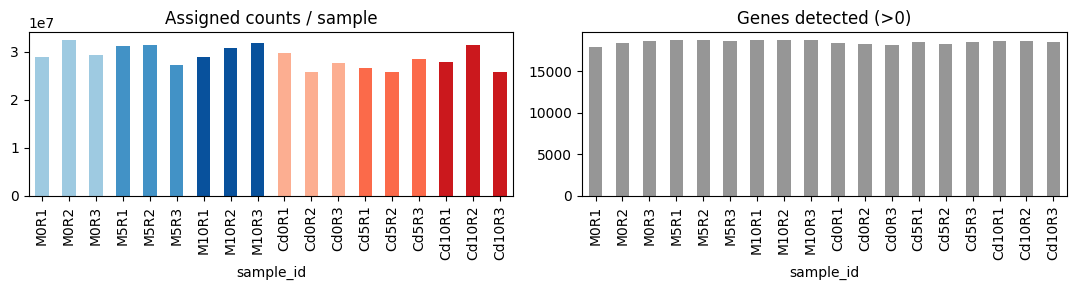

In [3]:
fig, axes = plt.subplots(1,2, figsize=(11,3))
counts_f.sum(0).reindex(meta.index).plot.bar(ax=axes[0], color=[ac.GROUP_COLORS[g] for g in meta['group']])
axes[0].set_title('Assigned counts / sample')
(counts_f>0).sum(0).reindex(meta.index).plot.bar(ax=axes[1], color='#969696')
axes[1].set_title('Genes detected (>0)'); plt.tight_layout(); plt.show()

## PCA on log-CPM

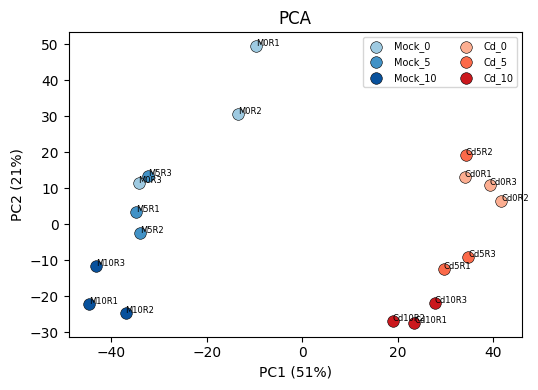

In [4]:
ln = ac.lognorm_cpm(counts_f)               # genes x samples
X = (ln.T - ln.T.mean(0)).values
U,S,Vt = np.linalg.svd(X, full_matrices=False)
var = (S**2)/np.sum(S**2)*100
pcs = U[:,:3]*S[:3]
fig, ax = plt.subplots(figsize=(5.5,4))
for g in ac.GROUP_ORDER:
    sel = (meta['group']==g).values
    ax.scatter(pcs[sel,0], pcs[sel,1], c=ac.GROUP_COLORS[g], label=g, s=70, edgecolor='k', lw=.4)
for i,s in enumerate(meta.index): ax.annotate(s,(pcs[i,0],pcs[i,1]),fontsize=6)
ax.set_xlabel(f'PC1 ({var[0]:.0f}%)'); ax.set_ylabel(f'PC2 ({var[1]:.0f}%)')
ax.legend(fontsize=7,ncol=2); ax.set_title('PCA'); plt.tight_layout(); plt.show()

## Sample–sample correlation

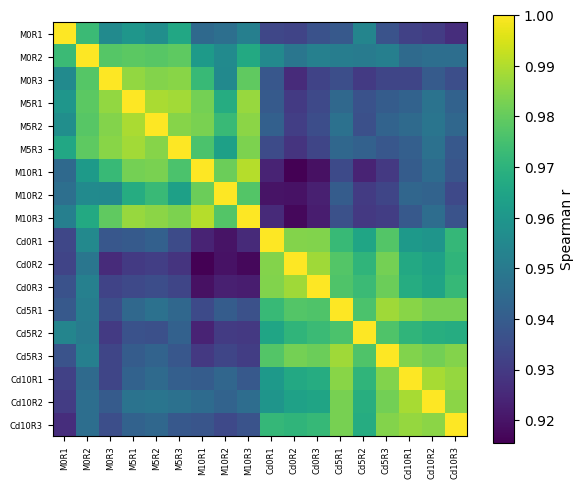

In [5]:
corr = ln.corr(method='spearman').loc[meta.index, meta.index]
fig, ax = plt.subplots(figsize=(6,5))
im = ax.imshow(corr.values, cmap='viridis')
ax.set_xticks(range(len(meta))); ax.set_xticklabels(meta.index, rotation=90, fontsize=6)
ax.set_yticks(range(len(meta))); ax.set_yticklabels(meta.index, fontsize=6)
fig.colorbar(im, ax=ax, label='Spearman r'); plt.tight_layout(); plt.show()

**Read-out:** PC1/PC2 should separate infection and/or butyrate. With a single donor there is no donor axis to worry about; if one replicate sits far from its group, note it as a possible outlier.